In [ ]:
import os

print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'ecommerce_customer_data_large.csv.zip', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = '/content/ecommerce_customer_data_large.csv.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())
    zip_ref.extractall('/content/')

print("Extraction completed!")

['ecommerce_customer_data_custom_ratios.csv', 'ecommerce_customer_data_large.csv']
Extraction completed!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/ecommerce_customer_data_large.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (250000, 13)


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,44605,2023-05-03 21:30:02,Home,177,1,2427,PayPal,31,1.0,John Rivera,31,Female,0
1,44605,2021-05-16 13:57:44,Electronics,174,3,2448,PayPal,31,1.0,John Rivera,31,Female,0
2,44605,2020-07-13 06:16:57,Books,413,1,2345,Credit Card,31,1.0,John Rivera,31,Female,0
3,44605,2023-01-17 13:14:36,Electronics,396,3,937,Cash,31,0.0,John Rivera,31,Female,0
4,44605,2021-05-01 11:29:27,Books,259,4,2598,PayPal,31,1.0,John Rivera,31,Female,0


In [ ]:
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

DATA TYPES
Customer ID                int64
Purchase Date             object
Product Category          object
Product Price              int64
Quantity                   int64
Total Purchase Amount      int64
Payment Method            object
Customer Age               int64
Returns                  float64
Customer Name             object
Age                        int64
Gender                    object
Churn                      int64
dtype: object

MISSING VALUES
Customer ID                  0
Purchase Date                0
Product Category             0
Product Price                0
Quantity                     0
Total Purchase Amount        0
Payment Method               0
Customer Age                 0
Returns                  47382
Customer Name                0
Age                          0
Gender                       0
Churn                        0
dtype: int64

DUPLICATE ROWS
0


In [ ]:
print("AGE COLUMN COMPARISON")
print("Customer Age equals Age:", df["Customer Age"].equals(df["Age"]))

print("\nNUMERICAL SUMMARY")
display(df.describe().round(2))

print("\nRETURN VALUES")
print(df["Returns"].value_counts(dropna=False))

print("\nCHURN VALUES")
print(df["Churn"].value_counts(dropna=False))

AGE COLUMN COMPARISON
Customer Age equals Age: True

NUMERICAL SUMMARY


,Customer ID,Product Price,Quantity,Total Purchase Amount,Customer Age,Returns,Age,Churn
count,250000.00,250000.00,250000.00,250000.00,250000.00,202618.0,250000.00,250000.0
mean,25017.63,254.74,3.00,2725.39,43.80,0.5,43.80,0.2
std,14412.52,141.74,1.41,1442.58,15.36,0.5,15.36,0.4
min,1.00,10.00,1.00,100.00,18.00,0.0,18.00,0.0
25%,12590.00,132.00,2.00,1476.00,30.00,0.0,30.00,0.0
50%,25011.00,255.00,3.00,2725.00,44.00,1.0,44.00,0.0
75%,37441.25,377.00,4.00,3975.00,57.00,1.0,57.00,0.0
max,50000.00,500.00,5.00,5350.00,70.00,1.0,70.00,1.0



RETURN VALUES
Returns
1.0    101476
0.0    101142
NaN     47382
Name: count, dtype: int64

CHURN VALUES
Churn
0    199870
1     50130
Name: count, dtype: int64


In [ ]:
# Convert Purchase Date into datetime format
df["Purchase Date"] = pd.to_datetime(df["Purchase Date"])

print("DATE RANGE")
print("First purchase:", df["Purchase Date"].min())
print("Last purchase:", df["Purchase Date"].max())

print("\nPRODUCT CATEGORIES")
print(df["Product Category"].value_counts())

print("\nPAYMENT METHODS")
print(df["Payment Method"].value_counts())

print("\nGENDER DISTRIBUTION")
print(df["Gender"].value_counts())

DATE RANGE
First purchase: 2020-01-01 00:07:26
Last purchase: 2023-09-13 18:42:49

PRODUCT CATEGORIES
Product Category
Electronics    62630
Clothing       62581
Home           62542
Books          62247
Name: count, dtype: int64

PAYMENT METHODS
Payment Method
Credit Card    83547
PayPal         83441
Cash           83012
Name: count, dtype: int64

GENDER DISTRIBUTION
Gender
Male      125676
Female    124324
Name: count, dtype: int64


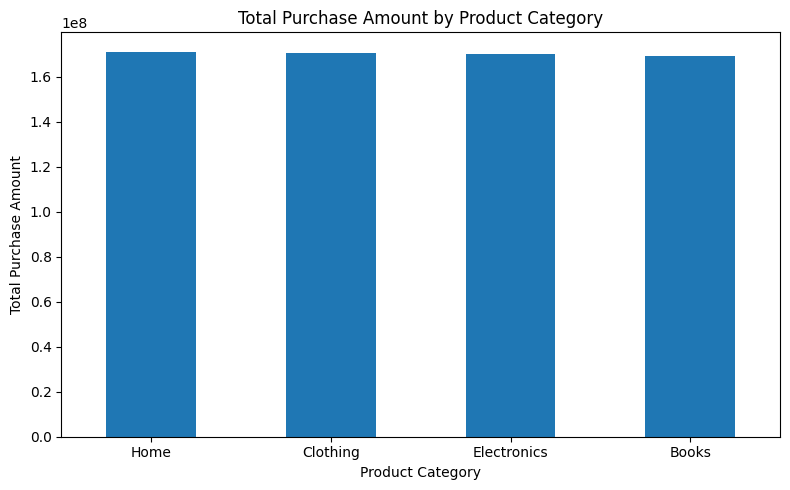

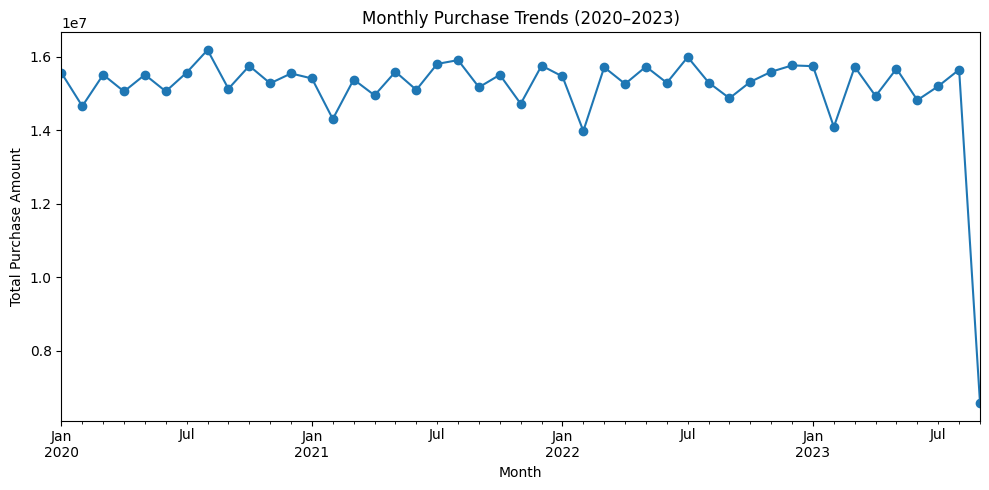

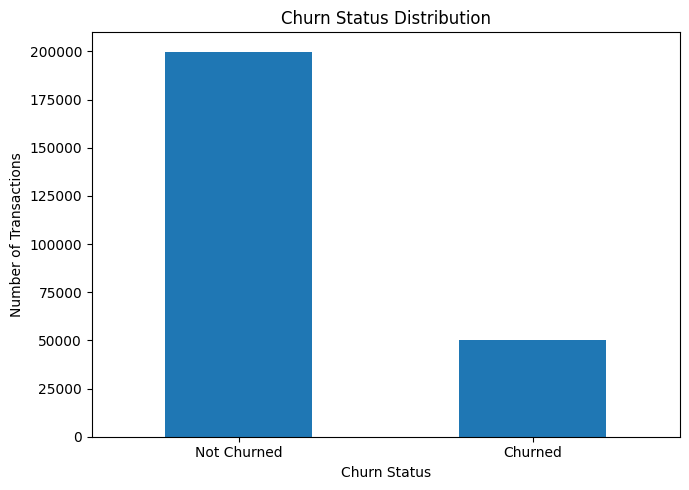

In [ ]:
# CHART 1: Total purchase amount by product category
category_sales = df.groupby('Product Category')['Total Purchase Amount'].sum().sort_values(ascending=False)

category_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Total Purchase Amount by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Purchase Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# CHART 2: Monthly purchase trends
monthly_sales = df.set_index('Purchase Date').resample('ME')['Total Purchase Amount'].sum()

monthly_sales.plot(kind='line', figsize=(10, 5), marker='o')
plt.title('Monthly Purchase Trends (2020–2023)')
plt.xlabel('Month')
plt.ylabel('Total Purchase Amount')
plt.tight_layout()
plt.show()


# CHART 3: Churn status distribution
churn_counts = df['Churn'].map({0: 'Not Churned', 1: 'Churned'}).value_counts()

churn_counts.plot(kind='bar', figsize=(7, 5))
plt.title('Churn Status Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Create customer-level RFM data

snapshot_date = df["Purchase Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Last_Purchase=("Purchase Date", "max"),
    Frequency=("Purchase Date", "count"),
    Monetary=("Total Purchase Amount", "sum")
)

rfm["Recency"] = (
    snapshot_date - rfm["Last_Purchase"]
).dt.days

# Assign scores from 1 to 5
# Rank first to handle duplicate values safely

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Create interpretable customer segments
def assign_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] >= 4:
        return "Recent Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    else:
        return "Needs Attention"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

print("Total unique customers:", len(rfm))
print("\nCUSTOMER SEGMENT COUNTS")
print(rfm["Segment"].value_counts())

print("\nRFM SUMMARY")
display(rfm.head(10))

Total unique customers: 49661

CUSTOMER SEGMENT COUNTS
Segment
Needs Attention     14492
Loyal Customers     12388
Champions            8764
At Risk              8644
Recent Customers     5373
Name: count, dtype: int64

RFM SUMMARY


,Last_Purchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,,
1,2022-11-29 06:48:25,3,6290,289,2,1,1,211,Needs Attention
2,2023-07-03 17:26:19,6,16481,73,4,4,4,444,Champions
3,2023-02-03 03:58:07,4,9423,223,3,2,2,322,Needs Attention
4,2022-06-29 03:41:09,5,7826,442,1,3,2,132,At Risk
5,2022-07-16 04:08:09,5,9769,425,2,3,2,232,At Risk
6,2023-04-26 08:29:49,9,25428,141,3,5,5,355,Loyal Customers
7,2023-04-24 22:16:48,8,17825,142,3,5,4,354,Loyal Customers
8,2023-08-19 03:19:57,7,16245,26,5,4,4,544,Champions
9,2023-04-25 21:02:36,7,24621,141,3,4,5,345,Loyal Customers


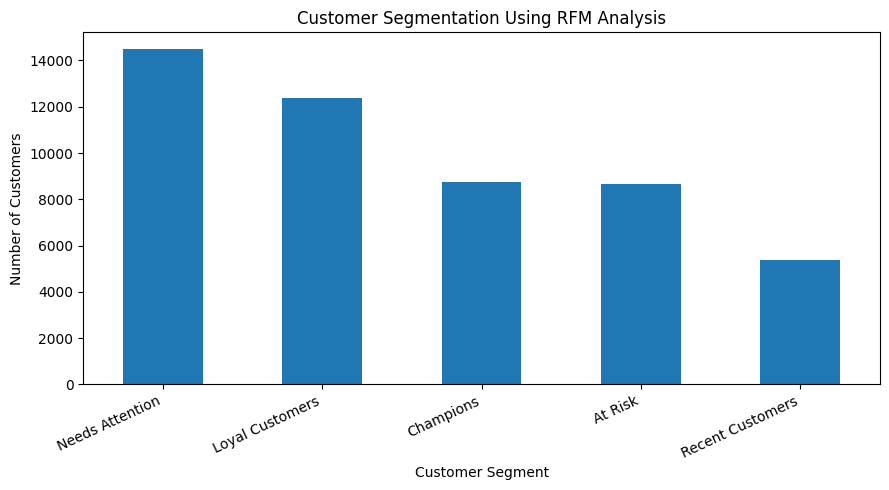

,Customers,Percentage
Segment,,
Needs Attention,14492,29.18
Loyal Customers,12388,24.95
Champions,8764,17.65
At Risk,8644,17.41
Recent Customers,5373,10.82


In [ ]:
# Customer segment distribution

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(9, 5))
segment_counts.plot(kind="bar")

plt.title("Customer Segmentation Using RFM Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Display counts and percentages
segment_summary = pd.DataFrame({
    "Customers": segment_counts,
    "Percentage": (segment_counts / len(rfm) * 100).round(2)
})

display(segment_summary)

In [ ]:
# Summarize churn at customer level
customer_churn = df.groupby("Customer ID").agg(
    Churn=("Churn", "max"),
    Transactions=("Purchase Date", "count"),
    Total_Spending=("Total Purchase Amount", "sum")
)

print("CUSTOMER-LEVEL CHURN")
print(customer_churn["Churn"].value_counts())

print("\nCUSTOMER CHURN RATE:")
print(round(customer_churn["Churn"].mean() * 100, 2), "%")

print("\nCHURN BY RFM SEGMENT")
rfm_churn = rfm[["Segment"]].join(customer_churn["Churn"])
display(
    rfm_churn.groupby("Segment")["Churn"]
    .agg(["sum", "count", "mean"])
    .assign(Churn_Percentage=lambda x: (x["mean"] * 100).round(2))
    .drop(columns="mean")
    .sort_values("Churn_Percentage", ascending=False)
)

CUSTOMER-LEVEL CHURN
Churn
0    39732
1     9929
Name: count, dtype: int64

CUSTOMER CHURN RATE:
19.99 %

CHURN BY RFM SEGMENT


,sum,count,Churn_Percentage
Segment,,,
Champions,1801,8764,20.55
Loyal Customers,2510,12388,20.26
Needs Attention,2903,14492,20.03
At Risk,1683,8644,19.47
Recent Customers,1032,5373,19.21


In [ ]:
# 1. Customer segment percentages
print("CUSTOMER SEGMENTS (%)")
print((rfm["Segment"].value_counts(normalize=True) * 100).round(2))

# 2. Average spending by segment
print("\nAVERAGE CUSTOMER SPENDING BY SEGMENT")
print(rfm.groupby("Segment")["Monetary"].mean().round(2).sort_values(ascending=False))

# 3. Average transaction frequency by segment
print("\nAVERAGE TRANSACTIONS BY SEGMENT")
print(rfm.groupby("Segment")["Frequency"].mean().round(2))

# 4. Customer churn rate
print("\nCUSTOMER CHURN RATE (%)")
print(round(customer_churn["Churn"].mean() * 100, 2))

# 5. Total recorded purchase amount
print("\nTOTAL RECORDED PURCHASE AMOUNT")
print(df["Total Purchase Amount"].sum())

CUSTOMER SEGMENTS (%)
Segment
Needs Attention     29.18
Loyal Customers     24.95
Champions           17.65
At Risk             17.41
Recent Customers    10.82
Name: proportion, dtype: float64

AVERAGE CUSTOMER SPENDING BY SEGMENT
Segment
Champions           21656.06
At Risk             16180.10
Loyal Customers     15359.15
Recent Customers     8853.82
Needs Attention      7856.14
Name: Monetary, dtype: float64

AVERAGE TRANSACTIONS BY SEGMENT
Segment
At Risk             5.94
Champions           7.62
Loyal Customers     5.87
Needs Attention     2.88
Recent Customers    3.25
Name: Frequency, dtype: float64

CUSTOMER CHURN RATE (%)
19.99

TOTAL RECORDED PURCHASE AMOUNT
681346299


In [ ]:
# Save customer segmentation results
rfm.to_csv("customer_rfm_segments.csv", index=True)

# Save segment summary
segment_summary.to_csv("customer_segment_summary.csv")

# Save customer churn analysis
rfm_churn.to_csv("customer_churn_by_segment.csv", index=True)

print("All three CSV files saved successfully!")

All three CSV files saved successfully!


In [ ]:
!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm

pdf_path = "/content/Customer_Behavior_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=1.6*cm,
    leftMargin=1.6*cm,
    topMargin=1.4*cm,
    bottomMargin=1.4*cm
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ProjectTitle",
    parent=styles["Title"],
    fontSize=19,
    leading=23,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#1677B8"),
    spaceAfter=8
))
styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    fontSize=11,
    leading=14,
    textColor=colors.HexColor("#1677B8"),
    spaceBefore=7,
    spaceAfter=4
))
styles.add(ParagraphStyle(
    name="Compact",
    parent=styles["BodyText"],
    fontSize=8.5,
    leading=11,
    spaceAfter=4
))

story = []

story.append(Paragraph(
    "Customer Behavior Analysis", styles["ProjectTitle"]
))
story.append(Paragraph(
    "Alfido Tech Data Analyst Internship | Executive Summary",
    styles["Normal"]
))
story.append(Spacer(1, 8))

story.append(Paragraph("Objective", styles["SectionHeading"]))
story.append(Paragraph(
    "Analyze e-commerce purchasing behavior, segment customers using "
    "Recency, Frequency and Monetary (RFM) analysis, examine recorded "
    "churn patterns, and recommend actions to improve engagement and retention.",
    styles["Compact"]
))

story.append(Paragraph("Dataset Overview", styles["SectionHeading"]))
story.append(Paragraph(
    f"The dataset contains {len(df):,} transaction records and "
    f"{df['Customer ID'].nunique():,} unique customers, covering "
    f"{df['Purchase Date'].min():%d %b %Y} to "
    f"{df['Purchase Date'].max():%d %b %Y}. "
    f"Total recorded purchase amount: "
    f"{df['Total Purchase Amount'].sum():,.0f} "
    "(currency not specified). No duplicate rows were found. "
    "The Returns column contains 47,382 missing values (18.95%).",
    styles["Compact"]
))

story.append(Paragraph("Key Findings", styles["SectionHeading"]))

findings = [
    f"Needs Attention: 14,492 customers ({14_492/len(rfm)*100:.2f}%).",
    f"Loyal Customers: 12,388 customers ({12_388/len(rfm)*100:.2f}%).",
    f"Champions: 8,764 customers; average recorded spending "
    f"{rfm.loc[rfm['Segment']=='Champions','Monetary'].mean():,.2f}.",
    f"At Risk: 8,644 customers, averaging "
    f"{rfm.loc[rfm['Segment']=='At Risk','Frequency'].mean():.2f} transactions.",
    f"Customer-level recorded churn rate: "
    f"{customer_churn['Churn'].mean()*100:.2f}%."
]
for item in findings:
    story.append(Paragraph("• " + item, styles["Compact"]))

story.append(Paragraph("RFM Segment Summary", styles["SectionHeading"]))
summary_data = [["Segment", "Customers", "Share (%)"]]
for segment, count in rfm["Segment"].value_counts().items():
    summary_data.append([
        segment,
        f"{count:,}",
        f"{count / len(rfm) * 100:.2f}%"
    ])

table = Table(summary_data, colWidths=[7.5*cm, 3.5*cm, 3.5*cm])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1677B8")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
    ("FONTSIZE", (0, 0), (-1, -1), 8),
    ("PADDING", (0, 0), (-1, -1), 4),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1),
     [colors.white, colors.HexColor("#EDF6FC")])
]))
story.append(table)

story.append(Paragraph("Five Recommendations", styles["SectionHeading"]))
recommendations = [
    "Re-engage Needs Attention customers using personalized reminders and relevant offers.",
    "Reward Champions with loyalty benefits and exclusive early access.",
    "Run measurable win-back campaigns for At Risk customers.",
    "Encourage repeat purchases with relevant recommendations and post-purchase follow-ups.",
    "Monitor churn monthly and investigate additional risk factors; RFM segments alone do not explain churn."
]
for i, recommendation in enumerate(recommendations, 1):
    story.append(Paragraph(
        f"{i}. {recommendation}", styles["Compact"]
    ))

story.append(Paragraph("Limitations", styles["SectionHeading"]))
story.append(Paragraph(
    "RFM segments are rule-based groups, not a validated churn prediction model. "
    "Churn was aggregated at customer level using the maximum recorded label; "
    "this assumes any positive transaction label marks that customer as churned. "
    "The churn definition should be verified. Missing return values were not "
    "imputed, and the final month contains only partial-month data.",
    styles["Compact"]
))

doc.build(story)
print("PDF report created:", pdf_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 24.2 MB/s eta 0:00:00
PDF report created: /content/Customer_Behavior_Analysis_Report.pdf


In [ ]:
from google.colab import files

files.download('/content/Customer_Behavior_Analysis_Report.pdf')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Check whether each customer's Churn label is consistent

churn_consistency = df.groupby("Customer ID")["Churn"].nunique()

print("Customers with consistent Churn labels:",
      (churn_consistency == 1).sum())

print("Customers with conflicting Churn labels:",
      (churn_consistency > 1).sum())

Customers with consistent Churn labels: 49661
Customers with conflicting Churn labels: 0


In [19]:
print("Total customers:", len(rfm))
print("Customers assigned to a segment:", rfm["Segment"].notna().sum())
print("Missing segment assignments:", rfm["Segment"].isna().sum())
print("Total customers across segments:", rfm["Segment"].value_counts().sum())

Total customers: 49661
Customers assigned to a segment: 49661
Missing segment assignments: 0
Total customers across segments: 49661
